In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from datasets import load_dataset
from guard import INJ_Q, INJ_OPTS, PII_Q, PII_OPTS
from minijev import ask

inj = load_dataset("deepset/prompt-injections", split="test")
inj_df = pd.DataFrame({"text": inj["text"], "label": inj["label"]})
inj_df["p"] = [ask(t[:1000], INJ_Q, INJ_OPTS)[INJ_OPTS[1]] for t in inj_df.text]

pii_df = pd.read_csv("pii_test.csv")
pii_df["p"] = [ask(t[:1000], PII_Q, PII_OPTS)[PII_OPTS[1]] for t in pii_df.text]

inj_df.to_csv("results/04_inj_probs.csv", index=False)
pii_df.to_csv("results/04_pii_probs.csv", index=False)

c:\code\llm-guardrail\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 311/311 [00:01<00:00, 167.61it/s]


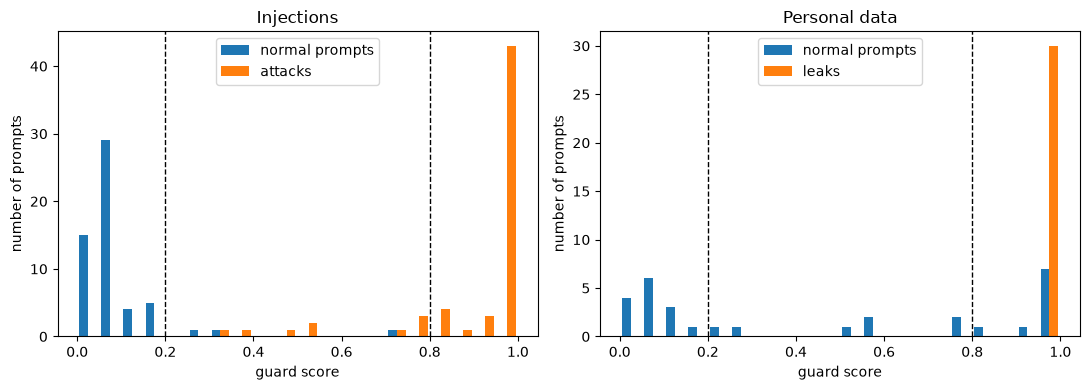

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

bins = np.linspace(0, 1, 21)
sets = [("Injections", inj_df, "attacks"), ("Personal data", pii_df, "leaks")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, df, pos) in zip(axes, sets):
    ax.hist([df.p[df.label == 0], df.p[df.label == 1]], bins=bins, label=["normal prompts", pos])
    for x in (0.2, 0.8):
        ax.axvline(x, color="black", linestyle="--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("guard score")
    ax.set_ylabel("number of prompts")
    ax.legend()
plt.tight_layout()
plt.savefig("results/04_score_histograms.png", dpi=150)
plt.show()

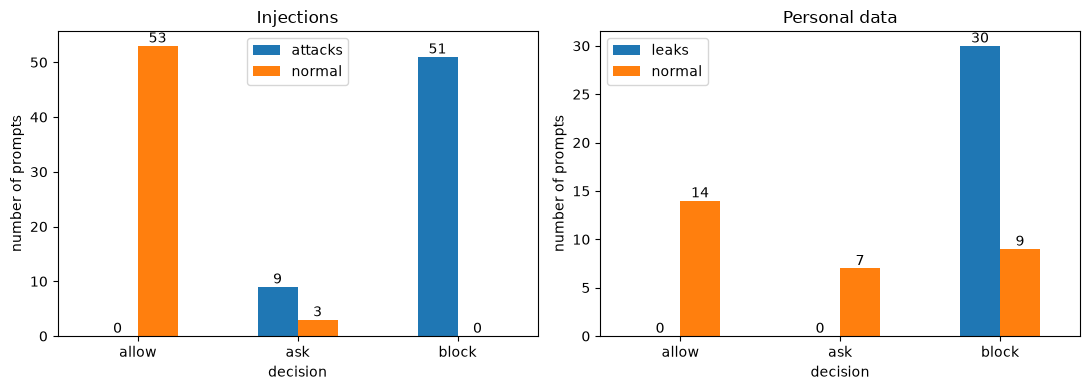

In [3]:
def band(p):
    return np.select([p < 0.2, p > 0.8], ["allow", "block"], "ask")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, df, pos) in zip(axes, sets):
    d = df.assign(decision=band(df.p), kind=df.label.map({0: "normal", 1: pos}))
    ct = pd.crosstab(d.decision, d.kind).reindex(["allow", "ask", "block"]).fillna(0).astype(int)
    ct.plot(kind="bar", ax=ax, rot=0)
    for c in ax.containers:
        ax.bar_label(c)
    ax.set_title(name)
    ax.set_xlabel("decision")
    ax.set_ylabel("number of prompts")
    ax.legend(title="")
plt.tight_layout()
plt.savefig("results/04_decisions.png", dpi=150)
plt.show()

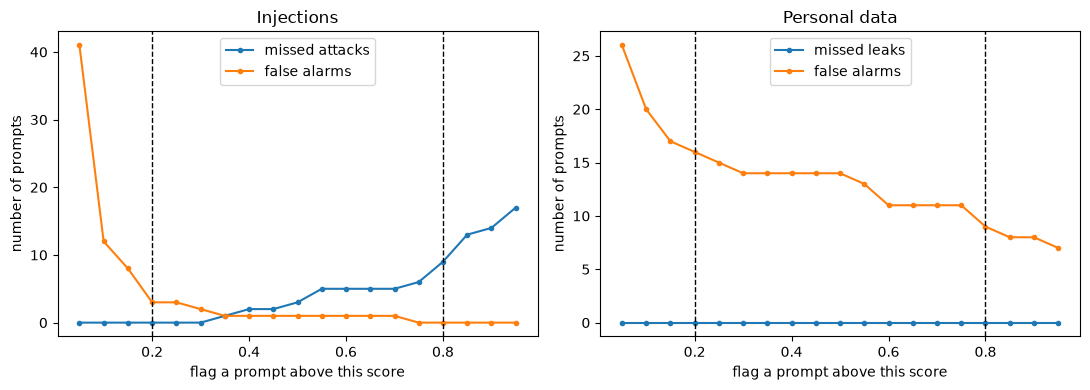

In [4]:
ts = np.round(np.arange(0.05, 1.0, 0.05), 2)

def sweep(df):
    return pd.DataFrame({
        "threshold": ts,
        "missed": [int(((df.p <= t) & (df.label == 1)).sum()) for t in ts],
        "false alarms": [int(((df.p > t) & (df.label == 0)).sum()) for t in ts]})

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, df, pos) in zip(axes, sets):
    s = sweep(df)
    ax.plot(s.threshold, s.missed, marker="o", markersize=3, label=f"missed {pos}")
    ax.plot(s.threshold, s["false alarms"], marker="o", markersize=3, label="false alarms")
    for x in (0.2, 0.8):
        ax.axvline(x, color="black", linestyle="--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("flag a prompt above this score")
    ax.set_ylabel("number of prompts")
    ax.legend()
plt.tight_layout()
plt.savefig("results/04_thresholds.png", dpi=150)
plt.show()

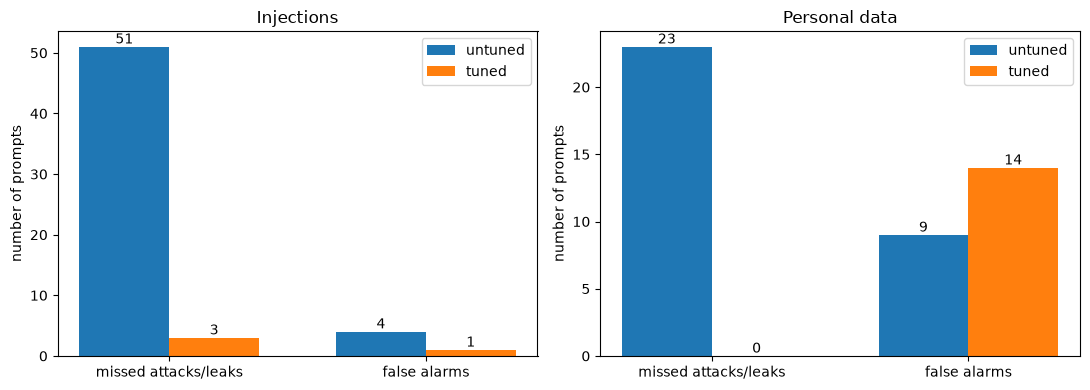

In [5]:
def errs(df, t=0.5):
    return int(((df.p <= t) & (df.label == 1)).sum()), int(((df.p > t) & (df.label == 0)).sum())

before = {"Injections": pd.read_csv("results/04_inj_probs_untuned.csv"),
          "Personal data": pd.read_csv("results/04_pii_probs_untuned.csv")}
after = {"Injections": inj_df, "Personal data": pii_df}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, before):
    b, a = errs(before[name]), errs(after[name])
    x, w = np.arange(2), 0.35
    ax.bar_label(ax.bar(x - w/2, b, w, label="untuned"))
    ax.bar_label(ax.bar(x + w/2, a, w, label="tuned"))
    ax.set_xticks(x)
    ax.set_xticklabels(["missed attacks/leaks", "false alarms"])
    ax.set_title(name)
    ax.set_ylabel("number of prompts")
    ax.legend()
plt.tight_layout()
plt.savefig("results/04_before_after.png", dpi=150)
plt.show()